![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Model-Agnostic Interpretation with LIME for Image Analysis

In this notebook, we will demonstrate how to use the Local Interpretable Model-Agnostic Explanations (LIME) method for image classification models.

--------

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. To start working on the notebook, click on the following button. This will open this page in the Colab environment, and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/2026-HIDA-Autumn/xai-for-cnn/3-Tutorial_LIME_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository
# and installed the requirements yourself.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch 2026-HIDA-Autumn https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-cnn.txt
    %cd xai-for-cnn


### Imports

Let's start with importing all required Python packages.

In [2]:
import numpy as np
from lime import lime_image
from skimage.segmentation import mark_boundaries

import torch
from torchvision import models
from torchvision.models.inception import Inception_V3_Weights

import sys
sys.path.append('./')
import utils

import matplotlib.pyplot as plt
%matplotlib inline

Now, we fix the random seeds to ensure reproducible results, as we work with (pseudo) random numbers.

In [3]:
# assert reproducible random number generation
seed = 1
np.random.seed(seed)
torch.manual_seed(seed)

--------

## Data and Model Loading

Let's use an image of an ananas.

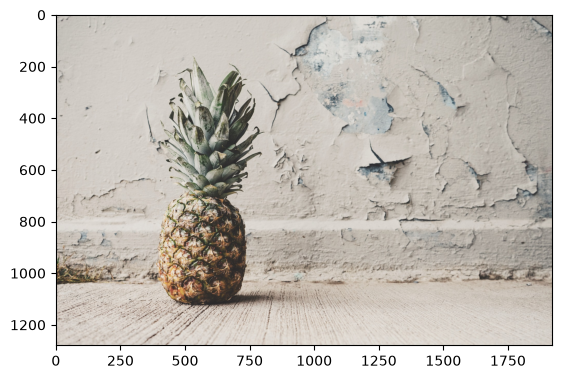

In [4]:
file_img = '../data/images/pineapple.jpg'

img = utils.read_image_PIL(file_img)
plt.imshow(img)

We have to apply some transformations to ensure the input data has the correct format and is optimized for model training and inference. If you want to know more about these transformations, you can have a look at the [*utils.py*](utils.py) file.

In [5]:
# load function to resize and center crop
pill_transf = utils.get_pil_transform()

As model, we choose the pre-trained Inception V3 architecture ([Szegedy et al., 2015](https://arxiv.org/pdf/1512.00567.pdf)) available along PyTorch. Inception V3 improved upon its predecessor by incorporating smaller kernel size, factorized convolution, auxiliary classifier, and batch normalization to improve efficiency, reduce the computational cost, and combat the vanishing gradient problem.

In [6]:
model = models.inception_v3(weights=Inception_V3_Weights.DEFAULT)

Predictions for a batch of images can be generated through the ```batch_predict``` function, which returns a batch of predicted probabilities for each class. Then, we extract the index of the class with the highest probability in the flattened array, indicating the predicted class label.

In [7]:
# Make prediction
pred = utils.batch_predict([pill_transf(img)], model)

# Extract class with highest prbability
top_class = pred.squeeze().argmax()
print(f"The predicted class with the highest probability is: {top_class}")

The predicted class with the highest probability is: 953


Get class name from [here](https://deeplearning.cms.waikato.ac.nz/user-guide/class-maps/IMAGENET/) and check if the prediction is correct.

## Now, what does my model think is important in the data?

**We prepared a small [Introduction to LIME](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/lime.html) for you, to help you understand how this method works. In the section [LIME for Image Classification](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/lime.html#lime-for-image-classification) we prepared an introduction on how to apply LIME on image data.**

*Note: we provide all references [here](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/lime.html#references).*

<font color='green'>

#### Question 1: What is a surrogate model?

<font color='grey'>

#### Your Answer: 


<font color='green'>

#### Question 2: How is LIME using surrogate models to explain a model prediction?

<font color='grey'>

#### Your Answer: 




Now, let's use LIME to get insights into the image classification model. To utilize LIME for image explanations, the first step is to instantiate the ```LimeImageExplainer()``` class. Subsequently, the ```explain_instance``` method is employed with the following parameters:

- ```image```: the image represented as a Numpy array.
- ```classifier_fn```: the model used for making predictions.
- ```segmentation_fn```: the model used for segmentation of superpixels. Segmentation models are taken from [scikit-image](https://scikit-image.org/docs/stable/api/skimage.segmentation.html).
- ```top_labels```: the number of top classes for which explanations are generated.
- ```hide_color```: the color assigned to non-activated superpixels (set to a specific color, or 'avg' to use the mean over the superpixel region).
- ```num_samples```: the size of the neighborhood to learn the linear model.
- ```random_seed```: to ensure reproducibility in the segmentation, set the random seed for consistent results.
  
For more details about all the possible parameters, check out the [LIME documentation](https://lime-ml.readthedocs.io/en/latest/lime.html#module-lime.lime_image).
 
In our specific instance, explanations are generated for the top 5 classes, and the background color for non-activated superpixels is set to black.

In [8]:
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(image=np.array(pill_transf(img)), 
                                         classifier_fn=lambda images: utils.batch_predict(images, model), 
                                         top_labels=5, 
                                         hide_color=None, 
                                         num_samples=1000,
                                         random_seed=42) 

  0%|          | 0/1000 [00:00<?, ?it/s]

To visualize the instance explanation, the ```get_image_and_mask``` method can be utilized with the following configurable parameters:

- ```label```: the label for which the explanation is desired.
- ```positive_only```: if ```True```, considers only superpixels that positively contribute to the prediction of the label.
- ```negative_only```: if ```True```, considers only superpixels that negatively contribute to the prediction of the label. If ```False```, both negative and positive contributions are considered. Note that both cannot be ```True``` simultaneously.
- ```hide_rest```: if ```True```, renders the non-explanation part of the return image in gray.
- ```num_features```: the number of superpixels to include in the explanation.
-  ```min_weight```: minimum weight of the superpixels to include in the explanation 
   
We will show three scenarios: one where positive contributions (```positive_only```)are active, another where negative contributions (```negative_only```) are active, and a third where both are included simultaneously (both set to False).

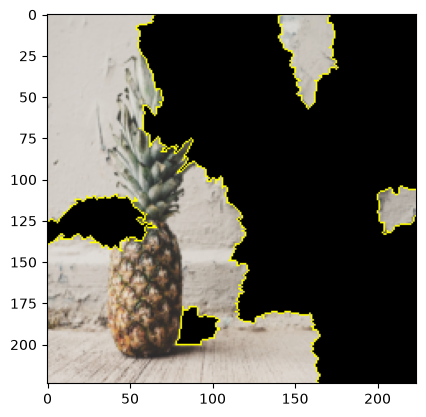

In [9]:
# Plot mask with positive contributions
label_to_explain = 0
temp, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[label_to_explain],
    positive_only=True,
    negative_only=False,
    num_features=10,
    hide_rest=True,
    min_weight=0,
)
normalized_temp = temp / 255.0
img_boundry1 = mark_boundaries(normalized_temp, mask)
plt.imshow(img_boundry1)

In this first example, we set ```num_features=10```, meaning that we want to extract the top 10 features (segmented areas) that contribute most to predicting the ananas. In other words, our model heavily depends on the ten segmented areas to recognize the ananas in the image. Try to change this parameter and see what happens.

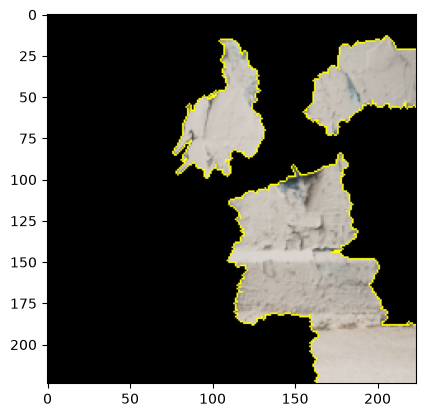

In [10]:
# Plot mask with negative contributions
temp, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[label_to_explain],
    positive_only=False,
    negative_only=True,
    num_features=10,
    hide_rest=True,
    min_weight=0,
)
normalized_temp = temp / 255.0
img_boundry2 = mark_boundaries(normalized_temp, mask)
plt.imshow(img_boundry2)

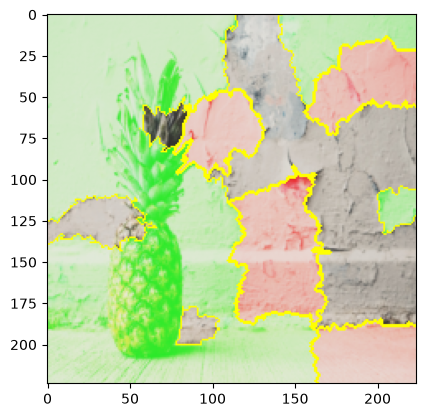

In [11]:
# Plot mask with both positive and negative contributions
temp, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[label_to_explain],
    positive_only=False,
    negative_only=False,
    num_features=20, # increased to show more superpixels
    hide_rest=False,
    min_weight=0,
)
normalized_temp = temp/255.0
img_boundry3 = mark_boundaries(normalized_temp, mask)
plt.imshow(img_boundry3)

**Fidelity of the explanation**

As in the Random Forest LIME notebook ([*Gen-2-Tutorial_LIME.ipynb*](../xai-for-random-forest/Gen-2-Tutorial_LIME.ipynb)), we can quantify how well the simple surrogate model approximates the predictions of the complex model in the neighborhood of our instance — the explanation's **fidelity**. LIME fits a weighted linear model on the perturbed images, and the goodness of fit of that surrogate is stored in `explanation.score` as an $R^2$ value (it refers to the top predicted class, i.e. the one we visualized above). The closer the $R^2$ is to 1, the better the surrogate reproduces the model's behavior on the neighborhood samples, and the more we can trust the explanation.

*Note: for image data this $R^2$ is usually **considerably lower** than in the tabular Random Forest case. Approximating a deep CNN with a linear model over a few hundred on/off superpixel perturbations is a much coarser approximation than fitting a linear model to a handful of tabular features, so a modest value here is expected — it is a reminder to interpret image LIME explanations with extra caution, not a sign that something went wrong.*

In [12]:
# Fidelity of the local surrogate model: the R^2 of LIME's linear approximation
# for the top predicted class. As in the Random Forest notebook, values closer
# to 1 mean a better approximation; for image LIME this is typically lower.
explanation.score

0.5911100448376905

<font color='green'>

#### Question 3: What are the pros and cons of LIME?

<font color='grey'>

#### Your Answer: 


<font color='green'>

#### Question 4: How do you think that the number of perturbed samples influences the stability of LIME explanations for image predictions?

<font color='grey'>

#### Your Answer:


<font color='green'>

#### Question 5: In the context of LIME for images, why do we perturb the input image by changing regions (superpixels) before generating explanations?

<font color='grey'>

#### Your Answer:




--------

<font color='green'>

#### Task: Apply LIME to a New Image

In this exercise, you will apply **LIME** to a new image containing both a cat and a dog in order to investigate how the trained ResNet50 model interprets the different objects in the scene.

Your task is to:

1. Load and preprocess the new image.
2. Run inference with the trained ResNet50 model and inspect the top predicted classes.
3. Identify the top predicted cat-related class and the highest-ranked dog-related class.
4. Generate LIME explanations for both classes separately.
5. Visualize and compare the resulting explanations.
6. Analyze which image regions contribute to the model predicting a cat-like class versus a dog-related class.

> **Hint:** LIME explanations are class-specific. The highlighted image regions may therefore differ substantially depending on which target class is explained. Compare whether the model focuses on different parts of the image when explaining the cat-related prediction versus the dog-related prediction.


In [ ]:
import json
import requests

path_to_img = '../data/images/cat_and_dog.jpg'
img = utils.read_image_PIL(path_to_img)

# Make prediction and print top-10 classes and labels
pred = utils.batch_predict([pill_transf(img)], model)

# Fetch ImageNet class labels
imagenet_classes_url = 'https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json'
response = requests.get(imagenet_classes_url)
class_labels = json.loads(response.text)

# Getting the top 10 predicted classes and their probabilities
top_10_classes = pred.squeeze().argsort()[-10:][::-1]  # Indices of top 5 classes
print("Top 10 predicted classes with their label and class names:")
for i in range(10):
    class_idx = top_10_classes[i]
    class_name = class_labels[class_idx]
    print(f"Class {i}: label {class_idx} - {class_name}")


In [ ]:
# add your code here
...